# Empirical Bayes & Hierarchical Shrinkage Across Series
> *Reference: Paraphrased from David Robinson's Introduction to Empirical Bayes.*

In many real-world settings, we have multiple groups with very unequal sample sizes.
Small-sample groups often exhibit extreme, volatile estimates purely due to measurement noise.
**Empirical Bayes partial pooling (shrinkage)** borrows statistical strength across the entire ensemble of groups
by estimating a shared prior hyperparameter, then shrinking each noisy group toward the grand prior.

This notebook demonstrates complete shrinkage workflows across all three series types in `probability`:
1. **Beta-Binomial Empirical Bayes on `BooleanSeries`** (Binary success rates / baseball batting averages).
2. **Gamma-Poisson Empirical Bayes on `CountSeries`** (Event rates / microservice bug reports).
3. **Normal-Normal James-Stein Empirical Bayes on `RatioSeries`** (Continuous group means / retail store sales).

In [1]:
import set_paths
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from probability.distributions import Boolean, BooleanSeries, Count, CountSeries, Ratio, RatioSeries, Beta, Gamma, Normal

## 1. Beta-Binomial Shrinkage on `BooleanSeries`
Scenario: Estimating player batting averages across $12$ baseball players.
Veteran players have hundreds of at-bats, while rookies have only $2$ or $4$ at-bats (yielding extreme raw averages like $1.000$ or $0.000$).

In [2]:
np.random.seed(42)
players = {
    'Veteran_Star_A': [1] * 160 + [0] * 340,   # 500 AB, .320
    'Veteran_Solid_B': [1] * 125 + [0] * 375,  # 500 AB, .250
    'Veteran_Solid_C': [1] * 80 + [0] * 270,   # 350 AB, .229
    'Regular_D':       [1] * 55 + [0] * 145,   # 200 AB, .275
    'Regular_E':       [1] * 22 + [0] * 78,    # 100 AB, .220
    'Bench_Player_F':  [1] * 8 + [0] * 32,     # 40 AB,  .200
    'Backup_G':        [1] * 5 + [0] * 15,     # 20 AB,  .250
    'Pinch_Hitter_H':  [1] * 3 + [0] * 7,      # 10 AB,  .300
    'Rookie_Phenom_I': [1] * 3 + [0] * 0,      # 3 AB,  1.000 (Extreme!)
    'Rookie_Cold_J':   [0] * 4,                # 4 AB,   .000 (Extreme!)
}
bool_series = BooleanSeries({name: Boolean(pd.Series(arr)) for name, arr in players.items()})
prior_beta = bool_series.empirical_bayes_prior(method='mle')
print(f"Empirical Bayes Prior: Beta(alpha={prior_beta.alpha:.2f}, beta={prior_beta.beta:.2f})")
print(f"Prior Grand Mean:      {prior_beta.mean():.3f}")

Empirical Bayes Prior: Beta(alpha=67.33, beta=189.05)
Prior Grand Mean:      0.263


In [3]:
summary_bool = bool_series.shrinkage_summary(hdi=0.95, prior=prior_beta)
print('--- Beta-Binomial Shrinkage Table ---')
display_cols = ['n', 'k', 'raw_mean', 'shrunk_mean', '95% HDI lower', '95% HDI upper', 'weight_data']
summary_bool[display_cols].round(3)

--- Beta-Binomial Shrinkage Table ---


,n,k,raw_mean,shrunk_mean,95% HDI lower,95% HDI upper,weight_data
category,,,,,,,
Veteran_Star_A,500,160,0.320,0.301,0.268,0.333,0.661
Veteran_Solid_B,500,125,0.250,0.254,0.223,0.285,0.661
Veteran_Solid_C,350,80,0.229,0.243,0.209,0.277,0.577
Regular_D,200,55,0.275,0.268,0.228,0.309,0.438
Regular_E,100,22,0.220,0.251,0.206,0.296,0.281
Bench_Player_F,40,8,0.200,0.254,0.205,0.304,0.135
Backup_G,20,5,0.250,0.262,0.211,0.314,0.072
Pinch_Hitter_H,10,3,0.300,0.264,0.212,0.317,0.038
Rookie_Phenom_I,3,3,1.000,0.271,0.218,0.326,0.012


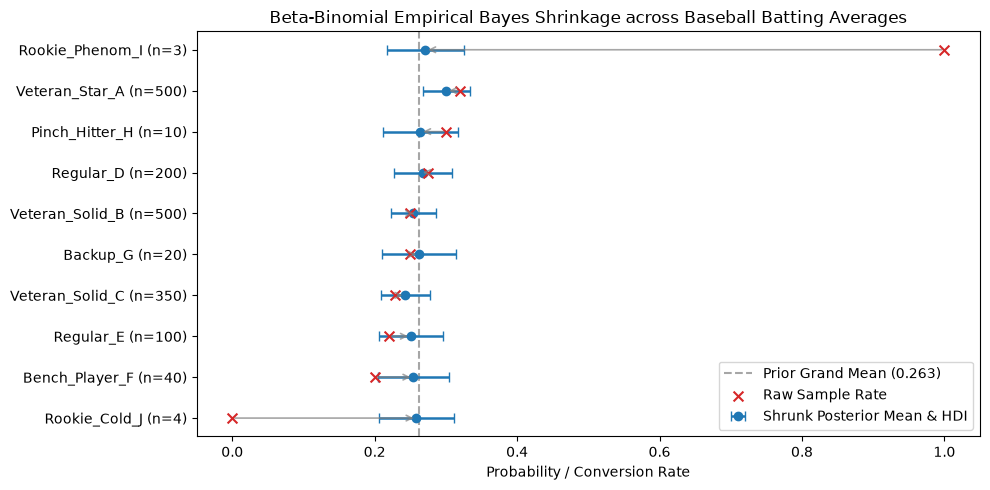

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
bool_series.plot_shrinkage(
    hdi=0.95,
    prior=prior_beta,
    ax=ax,
    order_by='raw_mean',
    title="Beta-Binomial Empirical Bayes Shrinkage across Baseball Batting Averages"
)
plt.tight_layout()

## 2. Gamma-Poisson Shrinkage on `CountSeries`
Scenario: Bug / incident reports observed across $10$ microservices.
Some legacy microservices have $300+$ hours of log exposure, while new microservices have only $1$ to $3$ hours of traffic.

In [5]:
services = {
    'Auth_API':        [1, 2, 1, 1, 2, 0, 1] * 50,  # 350 hrs, ~1.14/hr
    'Billing_Service': [2, 1, 3, 2, 1, 2, 1] * 30,  # 210 hrs, ~1.71/hr
    'Search_Indexer':  [3, 2, 1, 4, 2, 3] * 15,     # 90 hrs,  ~2.50/hr
    'Email_Worker':    [0, 1, 1, 0, 2, 1] * 8,      # 48 hrs,  ~0.88/hr
    'Recommendations': [2, 1, 0, 1, 3] * 4,         # 20 hrs,  ~1.40/hr
    'Mobile_Sync':     [4, 5],                      # 2 hrs,   ~4.50/hr (Extreme!)
    'Beta_Feature':    [0],                         # 1 hr,    ~0.00/hr (Extreme!)
}
count_series = CountSeries({name: Count(pd.Series(arr)) for name, arr in services.items()})
prior_gamma = count_series.empirical_bayes_prior(method='mle')
print(f"Empirical Bayes Prior: Gamma(alpha={prior_gamma.alpha:.2f}, beta={prior_gamma.beta:.2f})")
print(f"Prior Grand Mean Rate: {prior_gamma.mean():.3f} errors/hr")

Empirical Bayes Prior: Gamma(alpha=5.40, beta=3.23)
Prior Grand Mean Rate: 1.669 errors/hr


In [6]:
summary_count = count_series.shrinkage_summary(hdi=0.95, prior=prior_gamma)
print('--- Gamma-Poisson Shrinkage Table ---')
display_cols = ['exposure', 'total_count', 'raw_rate', 'shrunk_mean', '95% HDI lower', '95% HDI upper', 'weight_data']
summary_count[display_cols].round(3)

--- Gamma-Poisson Shrinkage Table ---


,exposure,total_count,raw_rate,shrunk_mean,95% HDI lower,95% HDI upper,weight_data
category,,,,,,,
Auth_API,350,400,1.143,1.148,1.037,1.260,0.991
Billing_Service,210,360,1.714,1.714,1.539,1.890,0.985
Search_Indexer,90,225,2.500,2.471,2.156,2.793,0.965
Email_Worker,48,40,0.833,0.886,0.636,1.148,0.937
Recommendations,20,28,1.400,1.437,0.967,1.933,0.861
Mobile_Sync,2,9,4.500,2.751,1.416,4.197,0.382
Beta_Feature,1,0,0.000,1.275,0.335,2.363,0.236


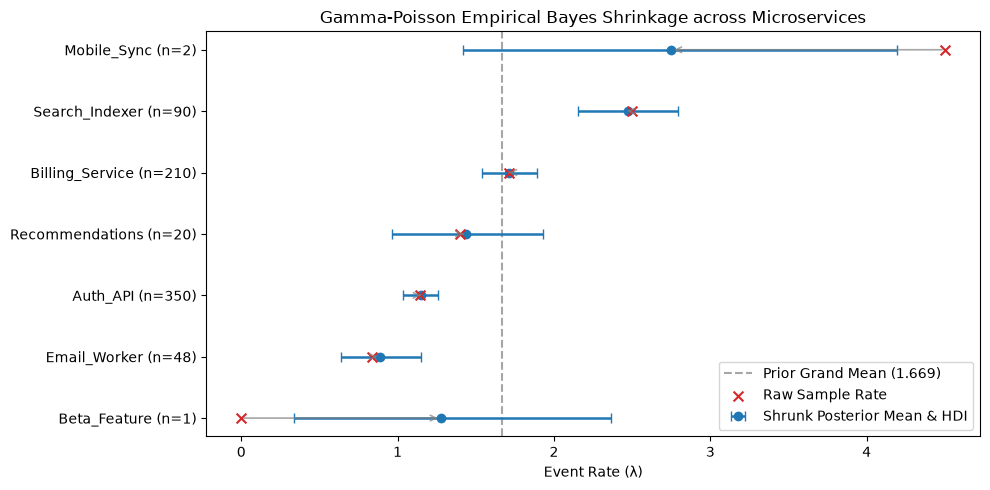

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
count_series.plot_shrinkage(
    hdi=0.95,
    prior=prior_gamma,
    ax=ax,
    order_by='raw_rate',
    title="Gamma-Poisson Empirical Bayes Shrinkage across Microservices"
)
plt.tight_layout()

## 3. Normal-Normal James-Stein Shrinkage on `RatioSeries`
Scenario: Average order value (AOV) across $9$ retail store locations.
Flagship stores have hundreds of transactions, while popup kiosks have $2$ or $3$ sales.

In [8]:
branches = {
    'Downtown_Flagship': np.random.normal(loc=82.0, scale=18.0, size=400),
    'Metro_Mall':        np.random.normal(loc=79.0, scale=17.0, size=250),
    'Westside_Center':   np.random.normal(loc=84.0, scale=19.0, size=150),
    'Suburban_Plaza':    np.random.normal(loc=76.0, scale=16.0, size=90),
    'University_Campus': np.random.normal(loc=72.0, scale=15.0, size=35),
    'Airport_PopUp':     np.array([125.0, 130.0, 120.0]),  # n=3, raw mean $125.0
    'Station_Kiosk':     np.array([40.0, 44.0]),            # n=2, raw mean $42.0
}
ratio_series = RatioSeries({name: Ratio(pd.Series(arr)) for name, arr in branches.items()})
prior_normal = ratio_series.empirical_bayes_prior(method='mle')
print(f"Empirical Bayes Prior: Normal(mu={prior_normal.mu:.2f}, sigma={prior_normal.sigma:.2f})")
print(f"Prior Grand Mean AOV:  ${prior_normal.mu:.2f}")

Empirical Bayes Prior: Normal(mu=81.07, sigma=22.13)
Prior Grand Mean AOV:  $81.07


In [9]:
summary_ratio = ratio_series.shrinkage_summary(hdi=0.95, prior=prior_normal)
print('--- Normal-Normal (James-Stein) Shrinkage Table ---')
display_cols = ['n', 'raw_mean', 'raw_se', 'shrunk_mean', 'shrunk_std', '95% HDI lower', '95% HDI upper', 'weight_data']
summary_ratio[display_cols].round(3)

--- Normal-Normal (James-Stein) Shrinkage Table ---


,n,raw_mean,raw_se,shrunk_mean,shrunk_std,95% HDI lower,95% HDI upper,weight_data
category,,,,,,,,
Downtown_Flagship,400,82.406,0.864,82.404,0.864,80.711,84.096,0.998
Metro_Mall,250,77.944,1.096,77.952,1.094,75.807,80.097,0.998
Westside_Center,150,84.024,1.533,84.010,1.529,81.013,87.007,0.995
Suburban_Plaza,90,79.005,1.609,79.016,1.605,75.869,82.162,0.995
University_Campus,35,77.493,1.958,77.521,1.950,73.699,81.344,0.992
Airport_PopUp,3,125.000,2.887,124.265,2.862,118.654,129.875,0.983
Station_Kiosk,2,42.000,2.000,42.317,1.992,38.413,46.221,0.992


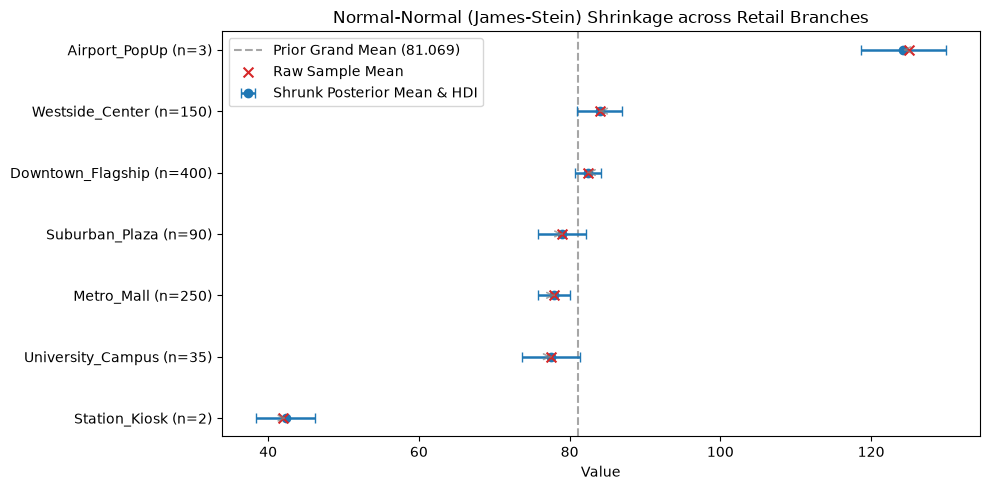

In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ratio_series.plot_shrinkage(
    hdi=0.95,
    prior=prior_normal,
    ax=ax,
    order_by='raw_mean',
    title="Normal-Normal (James-Stein) Shrinkage across Retail Branches"
)
plt.tight_layout()